# TP : Risque de crédit en Allemagne — repérer les mauvais risques avec des coûts d'erreur asymétriques





## 1. De quel type d'apprentissage s'agit-il ?

Le problème est le suivant : **à partir des caractéristiques d'un client et de son prêt (statut du compte, durée, montant, historique de crédit, âge, etc.), prédire s'il s'agit d'un bon ou d'un mauvais risque de crédit**.

Ce problème relève de l'**apprentissage supervisé**, plus précisément de la **classification binaire** :

- **Supervisé** : chaque dossier est associé à une étiquette connue (le crédit a-t-il été bien remboursé ou non ?). Le modèle apprend à partir de paires (entrée, sortie) déjà annotées.
- **Classification** : la cible \(y\) prend un nombre fini de valeurs, ici deux : bon risque (\(y=0\)) ou mauvais risque (\(y=1\)). Si la cible était le montant du prêt, ce serait une **régression**.
- **Binaire** : il n'y a que deux classes. On note « classe positive » le **mauvais risque**, car c'est lui que l'on cherche à repérer.

Ce TP a une particularité : **les deux types d'erreur n'ont pas le même coût**. Accorder un prêt à un client qui ne rembourse pas fait perdre une grande partie du capital ; refuser un client fiable ne fait perdre que la marge d'intérêts. L'exactitude (*accuracy*), qui compte toutes les erreurs de la même façon, n'est donc pas la bonne métrique. On travaillera avec l'**AUC** (qualité du classement des dossiers) et le **coût total** (conséquence financière d'une décision).

> **Remarque.** Le modèle ne décide pas seul : il produit une **probabilité** de mauvais risque. C'est ensuite un **seuil de décision**, choisi selon les coûts, qui transforme cette probabilité en « accepter » ou « refuser ». Séparer ces deux étapes est l'idée centrale du TP.

## 2. Le jeu de données

Le jeu de données **Statlog (German Credit Data)** a été constitué par le professeur Hans Hofmann (université de Hambourg). Il est publié par le dépôt **UCI Machine Learning Repository** (jeu n° 144) : <https://archive.ics.uci.edu/dataset/144>. Il décrit **1 000 dossiers** de crédit décrits par **20 variables** ; **300** sont des mauvais risques (30 %) et **700** des bons risques.

| N° | Nom utilisé ici | Type | Description |
|---|---|---|---|
| 1 | `statut_compte` | catégorielle | Situation du compte courant (en DM) |
| 2 | `duree_mois` | numérique | Durée du crédit (mois) |
| 3 | `historique_credit` | catégorielle | Historique de remboursement |
| 4 | `objet` | catégorielle | Objet du crédit (voiture, meubles, études…) |
| 5 | `montant` | numérique | Montant du crédit (DM) |
| 6 | `epargne` | catégorielle | Épargne / obligations |
| 7 | `anciennete_emploi` | catégorielle | Ancienneté dans l'emploi actuel |
| 8 | `taux_versement` | numérique | Mensualité en % du revenu disponible |
| 9 | `statut_personnel` | catégorielle | Situation personnelle et sexe |
| 10 | `autres_debiteurs` | catégorielle | Co-demandeur ou garant |
| 11 | `residence_depuis` | numérique | Ancienneté de résidence (années) |
| 12 | `bien` | catégorielle | Bien le plus précieux possédé |
| 13 | `age` | numérique | Âge (années) |
| 14 | `autres_plans` | catégorielle | Autres plans de crédit (banque, magasins) |
| 15 | `logement` | catégorielle | Locataire, propriétaire, logé gratuitement |
| 16 | `nb_credits` | numérique | Nombre de crédits existants dans la banque |
| 17 | `emploi` | catégorielle | Catégorie professionnelle |
| 18 | `nb_personnes_charge` | numérique | Nombre de personnes à charge |
| 19 | `telephone` | catégorielle | Téléphone enregistré au nom du client |
| 20 | `travailleur_etranger` | catégorielle | Travailleur étranger |
| — | `mauvais_risque` | cible binaire | 1 = mauvais risque, 0 = bon risque |

Dans la version d'origine, les variables catégorielles sont codées par des symboles (`A11`, `A12`, …). On les remplace par leur **libellé** pour que les graphiques et l'interprétation restent lisibles.

## Où et comment importer nos données

1. On télécharge le jeu de données sur <https://archive.ics.uci.edu/dataset/144> (bouton **Download**) : on obtient une archive `.zip` qui contient le fichier **`german.data`** (1 000 lignes, 21 colonnes séparées par des espaces, sans ligne d'en-tête).
2. On place `german.data` **dans le même dossier que ce notebook** (sur Google Colab : panneau « Fichiers » à gauche, puis « Importer »).
3. Dans la cellule **« ZONE À MODIFIER »** de la section suivante, on vérifie la variable `CHEMIN_FICHIER` (par défaut `"german.data"`). Si notre fichier est ailleurs ou a un autre nom, on la modifie, par exemple `"C:/Users/moi/Documents/german.data"`.
4. Alternative sans fichier : on met `MODE = "uci"` pour que le notebook télécharge lui-même les données depuis UCI (connexion Internet requise).

Une cellule de **vérification** contrôle ensuite que les données correspondent bien à la description : **1 000 dossiers, 20 variables, 300 mauvais risques**.

In [1]:
# Importation des bibliothèques
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, cross_val_score, cross_val_predict,
                                     learning_curve, StratifiedKFold)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from sklearn.inspection import permutation_importance

# Reproductibilité et style des graphiques
np.random.seed(42)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

In [2]:
# Chargement du jeu de données depuis une URL publique
URL = "https://raw.githubusercontent.com/Elminaouiilyass/2027-S7-FIN-2/43a8493866551543f8be6a792bc4e6cf6a44cfff/german.data"
df = pd.read_csv(URL)
print("Dimensions :", df.shape)
df.head=None

Dimensions : (999, 1)


In [3]:
# Rechargement correct : pas de ligne de titres dans le fichier, séparateur = espaces
NOMS = ["statut_compte", "duree_mois", "historique_credit", "objet", "montant", "epargne",
        "anciennete_emploi", "taux_versement", "statut_personnel", "autres_debiteurs",
        "residence_depuis", "bien", "age", "autres_plans", "logement", "nb_credits",
        "emploi", "nb_personnes_charge", "telephone", "travailleur_etranger"]

df = pd.read_csv(URL, sep=r"\s+", header=None, names=NOMS + ["classe"])
print("Dimensions :", df.shape)   # attendu : (1000, 21)
df.head()


Dimensions : (1000, 21)


,statut_compte,duree_mois,historique_credit,objet,montant,epargne,anciennete_emploi,taux_versement,statut_personnel,autres_debiteurs,...,bien,age,autres_plans,logement,nb_credits,emploi,nb_personnes_charge,telephone,travailleur_etranger,classe
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


In [4]:
# 1) Cible : dans le fichier, classe 1 = bon risque et 2 = mauvais risque.
#    On code 1 = mauvais risque (classe positive) et 0 = bon risque.
df["mauvais_risque"] = (df["classe"] == 2).astype(int)
df = df.drop(columns="classe")

# 2) Listes de variables utilisées par le prétraitement
variables_num = ["duree_mois", "montant", "taux_versement", "residence_depuis",
                 "age", "nb_credits", "nb_personnes_charge"]
variables_cat = [c for c in NOMS if c not in variables_num]

# 3) Remplacement des codes (A11, A12, ...) par des libellés lisibles
LIBELLES = {
    "statut_compte": {"A11": "< 0 DM", "A12": "0 à 200 DM", "A13": "≥ 200 DM", "A14": "pas de compte"},
    "historique_credit": {"A30": "aucun crédit / tout remboursé", "A31": "tout remboursé (cette banque)",
                          "A32": "remboursé normalement", "A33": "retard dans le passé",
                          "A34": "compte critique / autres crédits"},
    "objet": {"A40": "voiture neuve", "A41": "voiture d'occasion", "A42": "meubles", "A43": "radio/TV",
              "A44": "électroménager", "A45": "réparations", "A46": "études", "A47": "vacances",
              "A48": "reconversion", "A49": "entreprise", "A410": "autre"},
    "epargne": {"A61": "< 100 DM", "A62": "100 à 500 DM", "A63": "500 à 1000 DM", "A64": "≥ 1000 DM",
                "A65": "inconnue / aucune"},
    "anciennete_emploi": {"A71": "sans emploi", "A72": "< 1 an", "A73": "1 à 4 ans", "A74": "4 à 7 ans",
                          "A75": "≥ 7 ans"},
    "statut_personnel": {"A91": "homme divorcé/séparé", "A92": "femme divorcée/séparée/mariée",
                         "A93": "homme célibataire", "A94": "homme marié/veuf", "A95": "femme célibataire"},
    "autres_debiteurs": {"A101": "aucun", "A102": "co-demandeur", "A103": "garant"},
    "bien": {"A121": "immobilier", "A122": "assurance-vie / épargne-logement", "A123": "voiture / autre",
             "A124": "inconnu / aucun"},
    "autres_plans": {"A141": "banque", "A142": "magasins", "A143": "aucun"},
    "logement": {"A151": "locataire", "A152": "propriétaire", "A153": "logé gratuitement"},
    "emploi": {"A171": "non qualifié non résident", "A172": "non qualifié résident", "A173": "qualifié",
               "A174": "cadre / indépendant"},
    "telephone": {"A191": "non", "A192": "oui"},
    "travailleur_etranger": {"A201": "oui", "A202": "non"},
}
for colonne, table in LIBELLES.items():
    df[colonne] = df[colonne].map(table).fillna(df[colonne])

# 4) Contrôle des critères du TP
print("Dossiers :", df.shape[0], "(attendu : 1000)")
print("Variables :", df.shape[1] - 1, "(attendu : 20)")
print("Mauvais risques :", df["mauvais_risque"].sum(), "(attendu : 300)")
df.head()

Dossiers : 1000 (attendu : 1000)
Variables : 20 (attendu : 20)
Mauvais risques : 300 (attendu : 300)


,statut_compte,duree_mois,historique_credit,objet,montant,epargne,anciennete_emploi,taux_versement,statut_personnel,autres_debiteurs,...,bien,age,autres_plans,logement,nb_credits,emploi,nb_personnes_charge,telephone,travailleur_etranger,mauvais_risque
0,< 0 DM,6,compte critique / autres crédits,radio/TV,1169,inconnue / aucune,≥ 7 ans,4,homme célibataire,aucun,...,immobilier,67,aucun,propriétaire,2,qualifié,1,oui,oui,0
1,0 à 200 DM,48,remboursé normalement,radio/TV,5951,< 100 DM,1 à 4 ans,2,femme divorcée/séparée/mariée,aucun,...,immobilier,22,aucun,propriétaire,1,qualifié,1,non,oui,1
2,pas de compte,12,compte critique / autres crédits,études,2096,< 100 DM,4 à 7 ans,2,homme célibataire,aucun,...,immobilier,49,aucun,propriétaire,1,non qualifié résident,2,non,oui,0
3,< 0 DM,42,remboursé normalement,meubles,7882,< 100 DM,4 à 7 ans,2,homme célibataire,garant,...,assurance-vie / épargne-logement,45,aucun,logé gratuitement,1,qualifié,2,non,oui,0
4,< 0 DM,24,retard dans le passé,voiture neuve,4870,< 100 DM,1 à 4 ans,3,homme célibataire,aucun,...,inconnu / aucun,53,aucun,logé gratuitement,2,qualifié,2,non,oui,1


### Vérification des données importées

Avant d'aller plus loin, on contrôle que le jeu de données correspond bien à la description du TP : **1 000 dossiers, 20 variables, 300 mauvais risques**.

In [5]:
# Contrôle des critères du TP
n_dossiers, n_variables = df.shape[0], df.shape[1] - 1          # on retire la colonne cible
n_mauvais = int(df["mauvais_risque"].sum())
controles = [("dossiers", n_dossiers, 1000), ("variables", n_variables, 20), ("mauvais risques", n_mauvais, 300)]
for libelle, trouve, attendu in controles:
    print(("OK  " if trouve == attendu else "ÀVÉRIFIER  ") + f"{libelle} : {trouve} (attendu : {attendu})")
print(f"Part de mauvais risques : {n_mauvais / n_dossiers:.1%}")

OK  dossiers : 1000 (attendu : 1000)
OK  variables : 20 (attendu : 20)
OK  mauvais risques : 300 (attendu : 300)
Part de mauvais risques : 30.0%


## 3. Première exploration

Avant toute modélisation, on examine la structure des données : types des colonnes, valeurs manquantes et statistiques descriptives. Ces étapes servent à repérer les problèmes de qualité qui affecteront le modèle.

In [6]:
# Types des colonnes et nombre de valeurs non renseignées
df.info()
print("\nValeurs manquantes (total) :", int(df.isna().sum().sum()))
print("\nRépartition de la cible :")
print(df["mauvais_risque"].value_counts().rename({0: "bon risque", 1: "mauvais risque"}))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   statut_compte         1000 non-null   object
 1   duree_mois            1000 non-null   int64 
 2   historique_credit     1000 non-null   object
 3   objet                 1000 non-null   object
 4   montant               1000 non-null   int64 
 5   epargne               1000 non-null   object
 6   anciennete_emploi     1000 non-null   object
 7   taux_versement        1000 non-null   int64 
 8   statut_personnel      1000 non-null   object
 9   autres_debiteurs      1000 non-null   object
 10  residence_depuis      1000 non-null   int64 
 11  bien                  1000 non-null   object
 12  age                   1000 non-null   int64 
 13  autres_plans          1000 non-null   object
 14  logement              1000 non-null   object
 15  nb_credits            1000 non-null   i

In [7]:
# Statistiques descriptives des variables numériques
variables_num = ["duree_mois", "montant", "taux_versement", "residence_depuis",
                 "age", "nb_credits", "nb_personnes_charge"]
variables_cat = [c for c in NOMS if c not in variables_num]
print(len(variables_num), "variables numériques et", len(variables_cat), "variables catégorielles")
df[variables_num].describe().round(1)

7 variables numériques et 13 variables catégorielles


,duree_mois,montant,taux_versement,residence_depuis,age,nb_credits,nb_personnes_charge
count,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0,1000.0
mean,20.9,3271.3,3.0,2.8,35.5,1.4,1.2
std,12.1,2822.7,1.1,1.1,11.4,0.6,0.4
min,4.0,250.0,1.0,1.0,19.0,1.0,1.0
25%,12.0,1365.5,2.0,2.0,27.0,1.0,1.0
50%,18.0,2319.5,3.0,3.0,33.0,1.0,1.0
75%,24.0,3972.2,4.0,4.0,42.0,2.0,1.0
max,72.0,18424.0,4.0,4.0,75.0,4.0,2.0


**Lecture.** Le jeu de données compte **1 000 dossiers et 20 variables** et ne comporte **aucune valeur manquante** : il n'y a donc rien à imputer ni à supprimer. Sur les 20 variables, 7 sont numériques et 13 catégorielles. Les échelles des variables numériques sont très différentes : le montant se compte en milliers de DM, la durée en dizaines de mois, le nombre de crédits en unités. Cela justifiera une **mise à l'échelle**, indispensable pour une régression logistique régularisée.

## 4. Visualisation des données

### 4.1 Répartition des classes

Il faut vérifier si les deux classes sont équilibrées. Un déséquilibre rendrait l'exactitude trompeuse, et il pèsera aussi dans le calcul du coût.

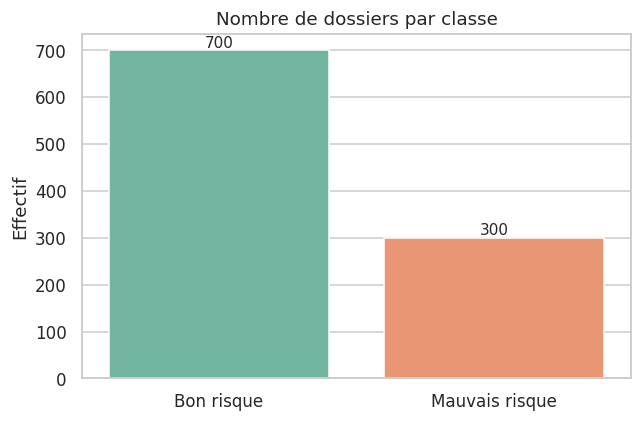

In [8]:
# Diagramme en barres du nombre de dossiers par classe
fig, ax = plt.subplots(figsize=(6, 4))
etiquettes = df["mauvais_risque"].map({0: "Bon risque", 1: "Mauvais risque"})
ordre = ["Bon risque", "Mauvais risque"]
sns.countplot(x=etiquettes, order=ordre, hue=etiquettes, hue_order=ordre, legend=False, ax=ax)
for patch in ax.patches:
    ax.annotate(f"{int(patch.get_height())}",
                (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Nombre de dossiers par classe")
ax.set_xlabel("")
ax.set_ylabel("Effectif")
plt.tight_layout()
plt.show()

**Lecture.** Les classes sont déséquilibrées : **700 bons risques (70 %) pour 300 mauvais risques (30 %)**. Nous utiliserons donc une **validation stratifiée**, qui conserve ces proportions dans chaque pli. Notez aussi qu'un « modèle » qui accepterait tous les dossiers aurait raison 7 fois sur 10 : l'exactitude serait flatteuse, alors que ce modèle accorderait tous les mauvais crédits.

### 4.2 Distributions des variables numériques selon la classe

Un histogramme par classe montre si une variable aide à distinguer les mauvais risques : plus les distributions sont séparées, plus la variable est informative.

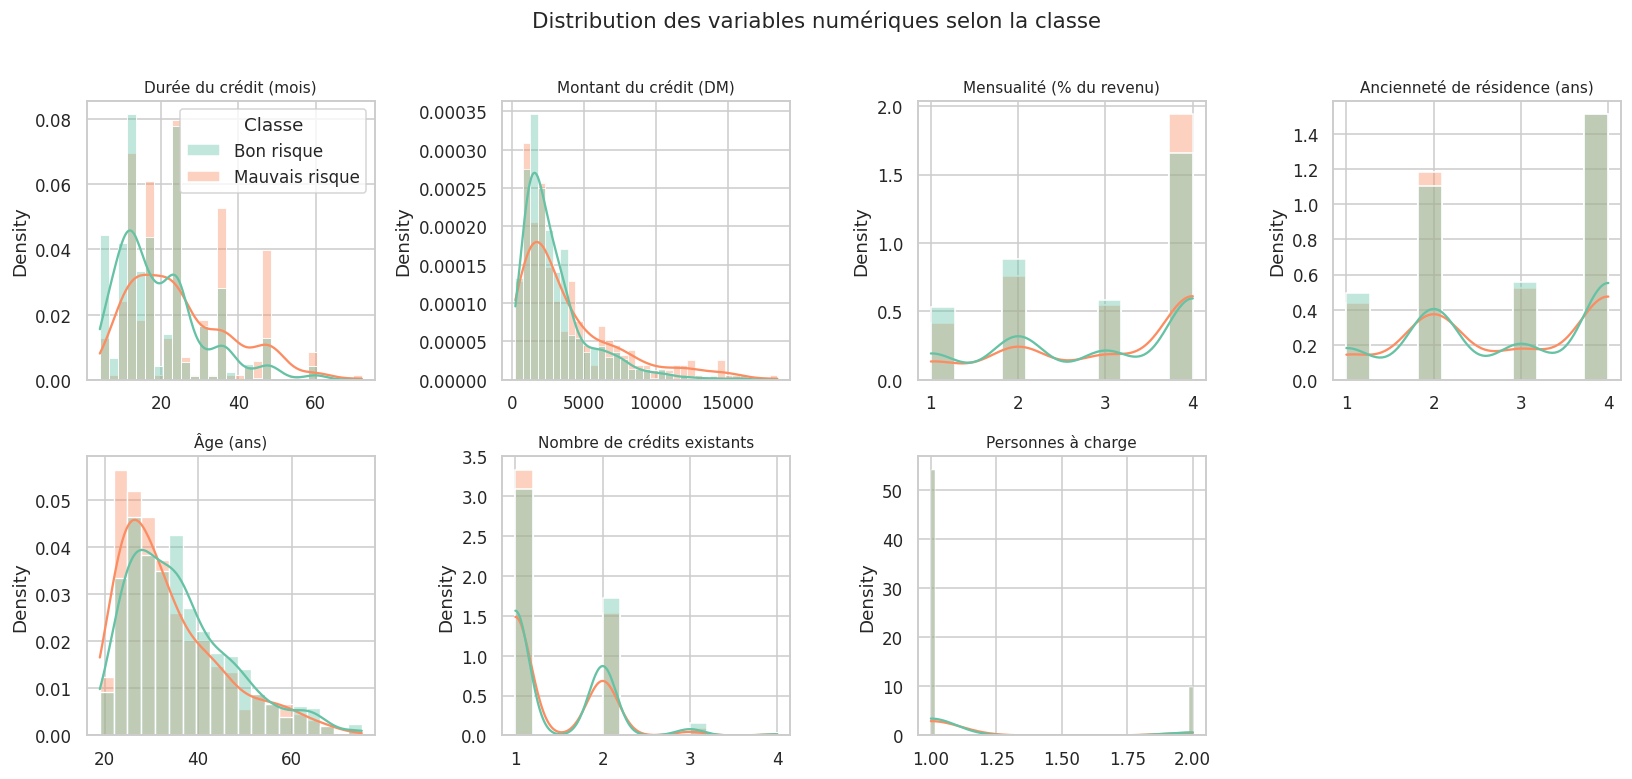

In [9]:
# Histogrammes superposés des variables numériques, par classe
titres_num = {"duree_mois": "Durée du crédit (mois)", "montant": "Montant du crédit (DM)",
              "taux_versement": "Mensualité (% du revenu)", "residence_depuis": "Ancienneté de résidence (ans)",
              "age": "Âge (ans)", "nb_credits": "Nombre de crédits existants",
              "nb_personnes_charge": "Personnes à charge"}
df_graph = df.assign(Classe=df["mauvais_risque"].map({0: "Bon risque", 1: "Mauvais risque"}))

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, var in zip(axes.ravel(), variables_num):
    sns.histplot(data=df_graph, x=var, hue="Classe", hue_order=ordre, stat="density",
                 common_norm=False, kde=True, alpha=0.4, ax=ax, legend=(var == "duree_mois"))
    ax.set_title(titres_num[var], fontsize=10)
    ax.set_xlabel("")
axes.ravel()[-1].axis("off")
plt.suptitle("Distribution des variables numériques selon la classe", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

**Lecture.** Les histogrammes sont normalisés (densité) pour comparer deux classes d'effectifs différents. Repérez les variables dont les deux courbes se décalent : ce sont les plus informatives. Les mauvais risques ont tendance à avoir des crédits **plus longs et plus élevés** ; les autres variables numériques (personnes à charge, ancienneté de résidence) séparent très peu les classes.

### 4.3 Taux de mauvais risque selon les variables catégorielles

Pour une variable catégorielle, on calcule la **part de mauvais risques dans chaque modalité**. La ligne verticale indique le taux global (30 %) : une modalité très à droite est à risque, une modalité très à gauche est sûre.

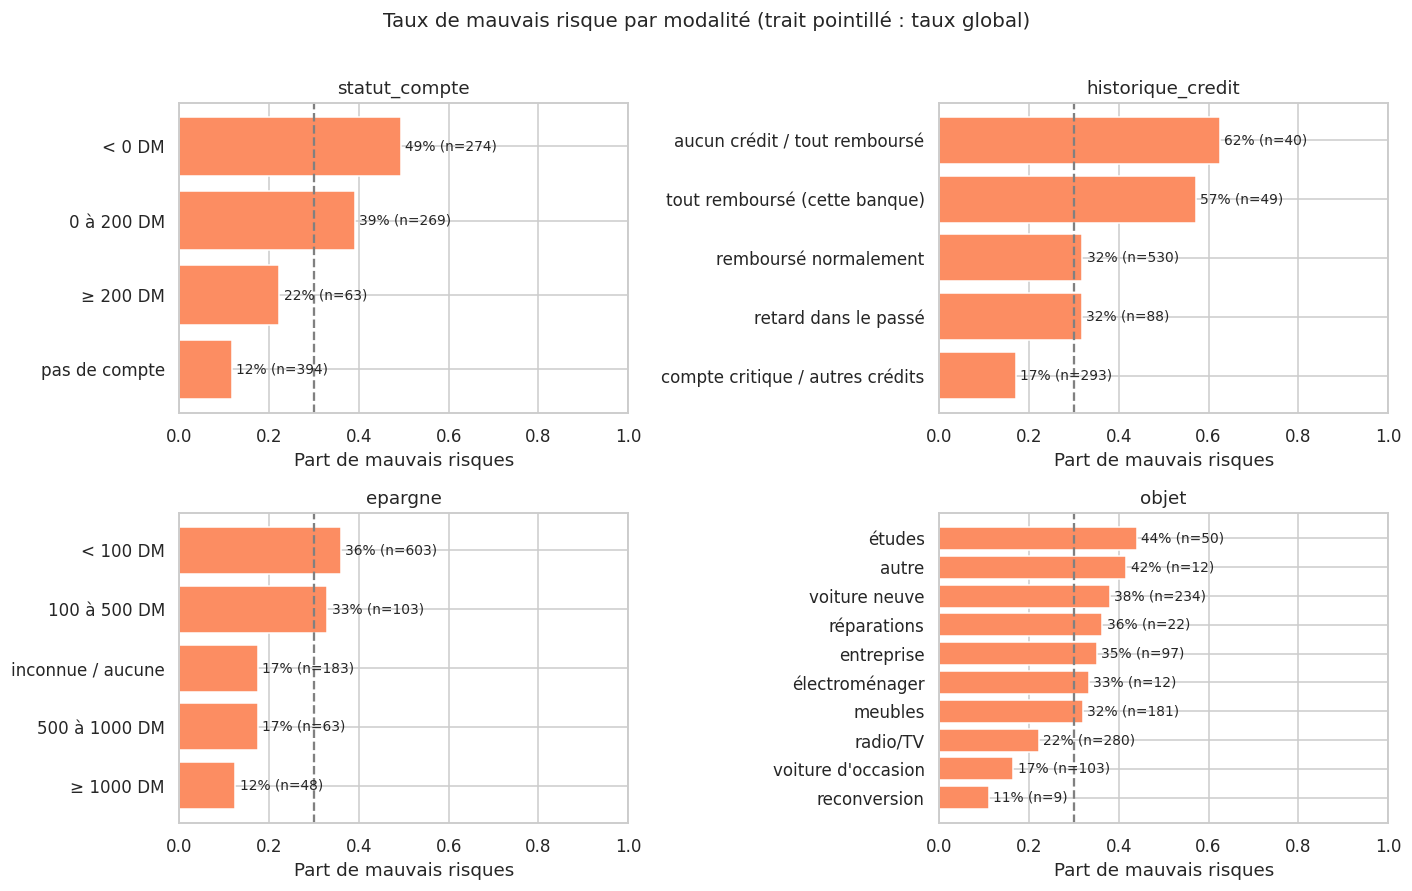

In [10]:
# Taux de mauvais risque par modalité, pour quatre variables catégorielles
choix = ["statut_compte", "historique_credit", "epargne", "objet"]
taux_global = df["mauvais_risque"].mean()

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, var in zip(axes.ravel(), choix):
    resume = df.groupby(var)["mauvais_risque"].agg(["mean", "size"]).sort_values("mean")
    ax.barh(resume.index, resume["mean"], color=sns.color_palette("Set2")[1])
    for i, (taux, n) in enumerate(zip(resume["mean"], resume["size"])):
        ax.text(taux + 0.01, i, f"{taux:.0%} (n={n})", va="center", fontsize=9)
    ax.axvline(taux_global, color="grey", linestyle="--")
    ax.set_xlim(0, 1)
    ax.set_title(var)
    ax.set_xlabel("Part de mauvais risques")
plt.suptitle("Taux de mauvais risque par modalité (trait pointillé : taux global)", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

**Lecture.** Le **statut du compte courant** est le signal le plus net : les clients dont le compte est à découvert (< 0 DM) sont beaucoup plus souvent de mauvais risques que ceux qui n'ont pas de compte. L'**historique de crédit** va dans un sens qui peut surprendre : un compte « critique » est associé à *moins* de défauts que « tout remboursé ». Ne concluez pas à une relation causale : ces effectifs sont petits (voir `n=`) et les variables sont liées entre elles. Pensez à regarder `n` avant d'interpréter un taux.

### 4.4 Boîtes à moustaches et corrélations

Les boîtes à moustaches résument la médiane, les quartiles et les valeurs extrêmes. La matrice de corrélation indique les liens linéaires entre variables numériques : deux variables très corrélées apportent une information redondante.

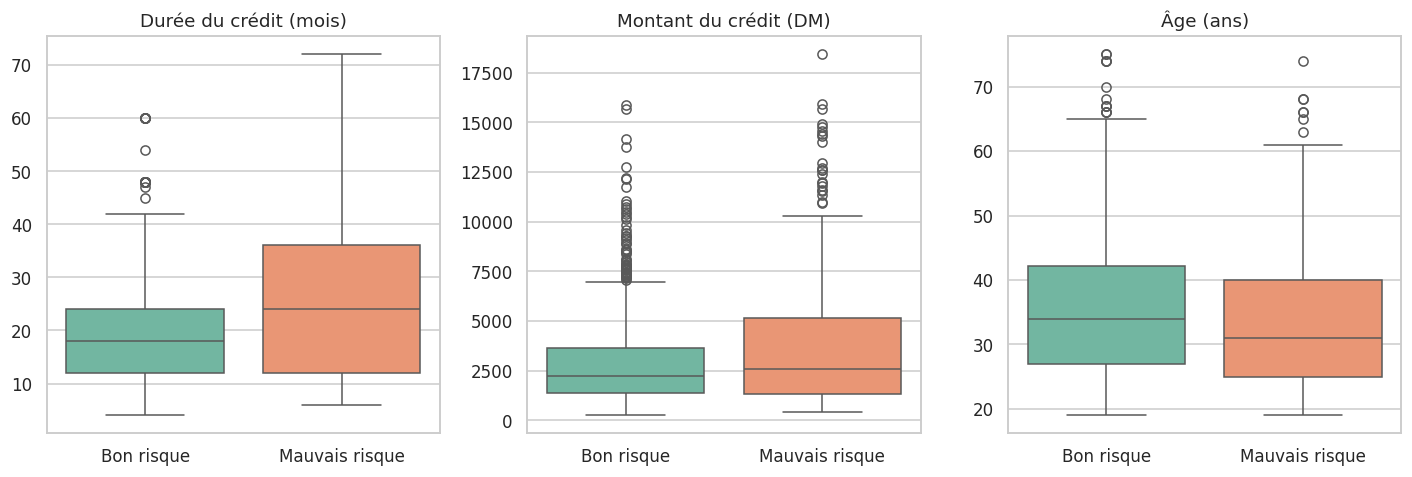

In [11]:
# Boîtes à moustaches pour les trois variables numériques les plus parlantes
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
for ax, var in zip(axes, ["duree_mois", "montant", "age"]):
    sns.boxplot(data=df_graph, x="Classe", y=var, order=ordre, hue="Classe", hue_order=ordre,
                legend=False, ax=ax)
    ax.set_title(titres_num[var])
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

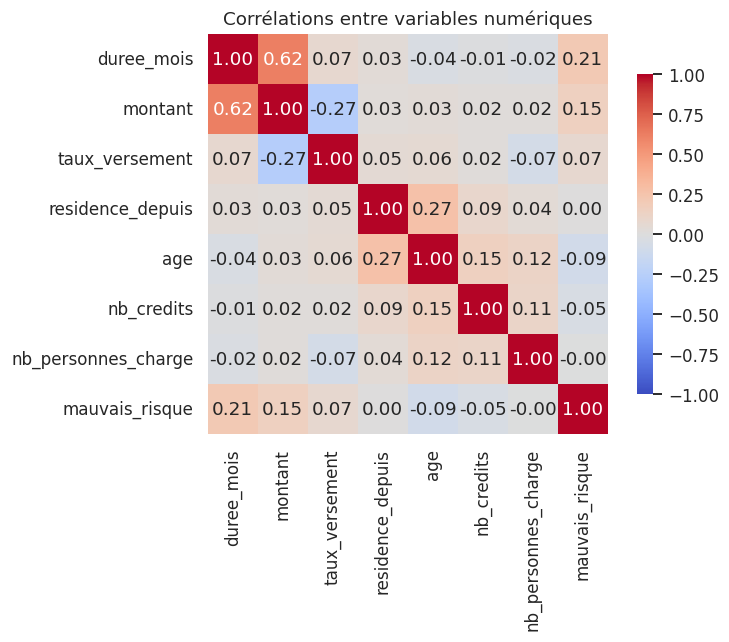

In [12]:
# Matrice de corrélation des variables numériques (et de la cible)
fig, ax = plt.subplots(figsize=(7.5, 6))
corr = df[variables_num + ["mauvais_risque"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Corrélations entre variables numériques")
plt.tight_layout()
plt.show()

**Lecture.** La **durée** et le **montant** sont corrélés positivement : un crédit plus élevé est en général plus long. Cette redondance n'est pas gênante pour un arbre ou une forêt, mais une régression logistique gagne à être régularisée. Les corrélations avec la cible restent modestes (aucune variable numérique ne suffit seule) : il faudra combiner les variables, y compris les catégorielles.

## 5. La matrice de coûts

Dans ce problème, **se tromper dans un sens coûte plus cher que dans l'autre**. On fixe donc une matrice de coûts avant de comparer les modèles, de façon à ne pas l'ajuster après coup pour favoriser un résultat.

| Réalité ↓ / Décision → | Accepter le prêt | Refuser le prêt |
|---|---|---|
| **Bon risque** | 0 | **1** (faux positif : manque à gagner) |
| **Mauvais risque** | **5** (faux négatif : perte de capital) | 0 |

**Justification.**

- **Refuser un bon client** (coût 1) : la banque ne perd pas d'argent, elle renonce à la marge d'intérêts du prêt. C'est le coût de référence, fixé à 1.
- **Accepter un mauvais client** (coût 5) : la banque perd une part importante du capital prêté, bien supérieure à la marge d'intérêts qu'elle aurait gagnée sur un bon client. Un ordre de grandeur de 5 pour 1 est cohérent avec une marge de quelques pour cent du montant face à une perte de plusieurs dizaines de pour cent du capital en cas de défaut.
- Ce rapport de 5 pour 1 est aussi celui que **la documentation du jeu de données UCI** propose pour ce jeu de données, ce qui rend les résultats comparables à la littérature.
- Les bonnes décisions (accepter un bon, refuser un mauvais) ne coûtent rien par convention.

**Conséquence sur le seuil.** Soit $p$ la probabilité de mauvais risque estimée par le modèle. En refusant, on perd $(1-p)\times c_{FP}$ en moyenne ; en acceptant, on perd $p\times c_{FN}$. Il vaut mieux refuser dès que $p\,c_{FN} > (1-p)\,c_{FP}$, c'est-à-dire dès que

$$p > t^* = \frac{c_{FP}}{c_{FP} + c_{FN}} = \frac{1}{1+5} \approx 0{,}167.$$

Le seuil « naturel » de 0,5 n'est donc **pas** adapté ici : avec ces coûts, il faut refuser un dossier dès qu'il a **1 chance sur 6** d'être mauvais. Ce seuil théorique $t^*$ n'est valable que si les probabilités du modèle sont bien calibrées ; nous le comparerons au seuil trouvé empiriquement.

**Politiques triviales de référence.** Sur les 1 000 dossiers, « tout accepter » coûte $5\times 300 = 1\,500$ et « tout refuser » coûte $1\times 700 = 700$. Un modèle n'est utile que s'il coûte **moins que 700** (en proportion, moins de 0,7 par dossier).

In [13]:
# Matrice de coûts (fixée une fois pour toutes) et fonctions associées
COUT_FN = 5   # accepter un mauvais risque (faux négatif)
COUT_FP = 1   # refuser un bon risque (faux positif)
seuil_theorique = COUT_FP / (COUT_FP + COUT_FN)
print(f"Seuil théorique t* = {COUT_FP}/({COUT_FP}+{COUT_FN}) = {seuil_theorique:.3f}")

seuils = np.linspace(0, 1, 201)

def cout_total(y_vrai, p_mauvais, seuil, c_fn=COUT_FN, c_fp=COUT_FP):
    """Coût total si l'on refuse tout dossier dont P(mauvais) >= seuil."""
    y_vrai = np.asarray(y_vrai)
    refuse = np.asarray(p_mauvais) >= seuil
    faux_negatifs = np.sum(~refuse & (y_vrai == 1))   # mauvais risques acceptés
    faux_positifs = np.sum(refuse & (y_vrai == 0))    # bons risques refusés
    return c_fn * faux_negatifs + c_fp * faux_positifs

def courbe_cout(y_vrai, p_mauvais, c_fn=COUT_FN, c_fp=COUT_FP):
    """Coût total pour chaque seuil de la grille."""
    return np.array([cout_total(y_vrai, p_mauvais, s, c_fn, c_fp) for s in seuils])

def seuil_optimal(cout):
    """Seuil de coût minimal (au milieu du palier si plusieurs seuils sont ex aequo)."""
    indices = np.flatnonzero(cout == cout.min())
    return seuils[indices[len(indices) // 2]]

def cout_trivial(y_vrai, c_fn=COUT_FN, c_fp=COUT_FP):
    """Coûts de « tout accepter » et de « tout refuser »."""
    y_vrai = np.asarray(y_vrai)
    return c_fn * np.sum(y_vrai == 1), c_fp * np.sum(y_vrai == 0)

tout_accepter, tout_refuser = cout_trivial(df["mauvais_risque"])
print(f"Sur les {len(df)} dossiers : tout accepter = {tout_accepter}, tout refuser = {tout_refuser}")

Seuil théorique t* = 1/(1+5) = 0.167
Sur les 1000 dossiers : tout accepter = 1500, tout refuser = 700


## 6. Préparation des données

Règles à respecter :

- **Ne jamais utiliser le jeu de test pendant la préparation.** Toute transformation (moyenne, écart-type, catégories) est apprise sur l'entraînement uniquement. Cela vaut aussi pour le **choix du seuil** : il sera fixé sans regarder le jeu de test.
- **Valeurs manquantes.** Il n'y en a aucune ici.
- **Encoder les variables catégorielles.** Un modèle ne lit pas le texte : chaque modalité devient une colonne 0/1 (*one-hot encoding*).
- **Standardiser les variables numériques** (montants, durées, âge…) : $z = \dfrac{x - \bar x}{s}$, moyenne nulle et écart-type 1.

Ces étapes sont regroupées dans un `Pipeline` : la même chaîne est alors appliquée à l'entraînement, à la validation et au test.

In [14]:
# 1) Séparation entrées / cible
X = df.drop(columns="mauvais_risque")
y = df["mauvais_risque"]

# 2) Découpage stratifié : 75 % entraînement, 25 % test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Entraînement :", X_train.shape[0], "| Test :", X_test.shape[0])
print("Part de mauvais risques : entraînement", round(y_train.mean(), 3), "| test", round(y_test.mean(), 3))

# 3) Prétraitement : standardisation des numériques, encodage des catégorielles
preprocesseur = ColumnTransformer([
    ("num", StandardScaler(), variables_num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), variables_cat),
])

Entraînement : 750 | Test : 250
Part de mauvais risques : entraînement 0.3 | test 0.3


## 7. Entraînement et comparaison de modèles

### 7.1 Principe de la comparaison

Nous comparons trois algorithmes, du plus simple au plus complexe :

1. la **régression logistique**, qui sert de **référence** : simple, rapide, et ses coefficients s'interprètent ;
2. un **arbre de décision** : des règles « si… alors… » faciles à lire, mais instables ;
3. une **forêt aléatoire** : de nombreux arbres moyennés, en général plus précis mais moins lisibles.

Pour chaque modèle, deux métriques sont calculées par **validation croisée stratifiée à 5 plis sur l'ensemble d'entraînement** (le jeu de test reste de côté) :

- l'**AUC** (aire sous la courbe ROC) : probabilité qu'un mauvais risque tiré au hasard reçoive une probabilité plus élevée qu'un bon risque tiré au hasard. 0,5 correspond au hasard, 1 à un classement parfait. L'AUC **ne dépend pas du seuil** et mesure la qualité du classement ;
- le **coût total** : obtenu à partir de **probabilités « hors pli »** (*out-of-fold*), c'est-à-dire que chaque dossier est noté par un modèle qui ne l'a jamais vu. On calcule alors le coût pour tous les seuils et on retient le seuil de coût minimal.

Les modèles sont ici utilisés sans pondération des classes : c'est le **seuil** qui prend en charge l'asymétrie des coûts.

In [15]:
# Modèles candidats, chacun précédé du même prétraitement
modeles = {
    "Régression logistique (référence)": LogisticRegression(max_iter=2000),
    "Arbre de décision": DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=42),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=300, min_samples_leaf=3,
                                              random_state=42, n_jobs=-1),
}
pipelines = {nom: Pipeline([("prep", preprocesseur), ("modele", m)]) for nom, m in modeles.items()}

validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_train_np = y_train.to_numpy()
proba_oof, courbes_oof, resultats = {}, {}, []

for nom, pipe in pipelines.items():
    auc_plis = cross_val_score(pipe, X_train, y_train, cv=validation, scoring="roc_auc")
    p = cross_val_predict(pipe, X_train, y_train, cv=validation, method="predict_proba")[:, 1]
    cout = courbe_cout(y_train_np, p)
    proba_oof[nom], courbes_oof[nom] = p, cout
    resultats.append({
        "Modèle": nom,
        "AUC moyenne": auc_plis.mean(),
        "Écart-type": auc_plis.std(),
        "Seuil optimal": seuil_optimal(cout),
        "Coût minimal": cout.min(),
        "Coût à 0,5": cout_total(y_train_np, p, 0.5),
        f"Coût à t* ({seuil_theorique:.3f})": cout_total(y_train_np, p, seuil_theorique),
    })

tableau = pd.DataFrame(resultats).sort_values("AUC moyenne", ascending=False).reset_index(drop=True)
t_acc, t_ref = cout_trivial(y_train_np)
print(f"Politiques triviales sur l'entraînement ({len(y_train)} dossiers) : "
      f"tout accepter = {t_acc}, tout refuser = {t_ref}")
tableau.round(3)

Politiques triviales sur l'entraînement (750 dossiers) : tout accepter = 1125, tout refuser = 525


,Modèle,AUC moyenne,Écart-type,Seuil optimal,Coût minimal,"Coût à 0,5",Coût à t* (0.167)
0,Forêt aléatoire,0.787,0.020,0.230,380,808,418
1,Régression logistique (référence),0.765,0.036,0.095,398,693,433
2,Arbre de décision,0.763,0.012,0.070,408,672,411


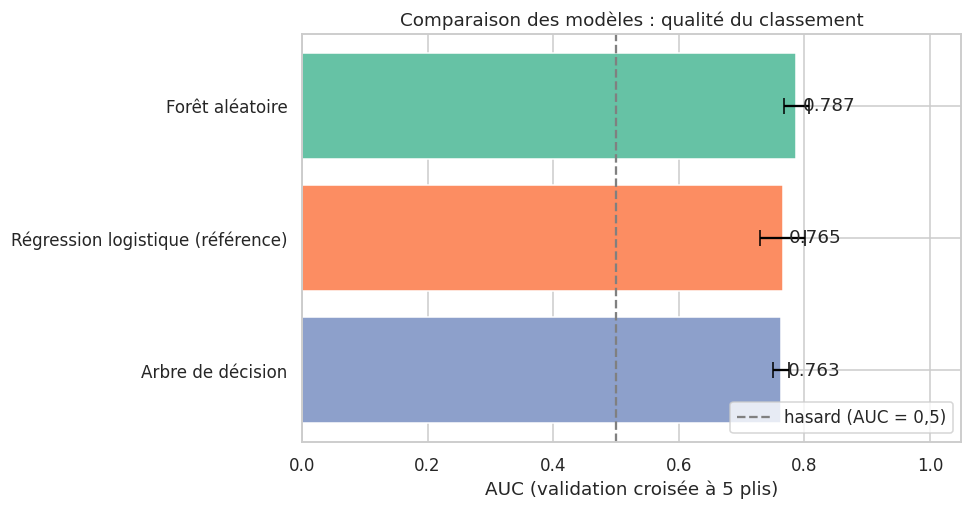

In [16]:
# Graphique : AUC moyenne en validation croisée, avec barres d'erreur
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(tableau["Modèle"], tableau["AUC moyenne"], xerr=tableau["Écart-type"],
        capsize=5, color=sns.color_palette("Set2", len(tableau)))
ax.set_xlim(0, 1.05)
ax.invert_yaxis()
ax.axvline(0.5, color="grey", linestyle="--", label="hasard (AUC = 0,5)")
for i, val in enumerate(tableau["AUC moyenne"]):
    ax.text(val + 0.01, i, f"{val:.3f}", va="center")
ax.set_xlabel("AUC (validation croisée à 5 plis)")
ax.set_title("Comparaison des modèles : qualité du classement")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Lecture.** Tous les modèles font mieux que le hasard (AUC > 0,5), mais l'écart entre eux est moins spectaculaire que pour un problème « facile » : le risque de crédit est un phénomène bruité, dans lequel les caractéristiques du dossier ne permettent qu'un classement imparfait. Comparez les **écarts-types** aux écarts entre modèles : si deux modèles ont des AUC qui diffèrent de moins d'un écart-type, on ne peut pas affirmer que l'un est meilleur. Comparez aussi la colonne « Coût minimal » à la politique triviale « tout refuser » : c'est le gain réel apporté par le modèle.

### 7.2 Courbe de coût selon le seuil de décision

C'est le **livrable central** du TP. Pour chaque seuil $t$ entre 0 et 1, on refuse les dossiers dont la probabilité de mauvais risque dépasse $t$, puis on calcule le coût total. À gauche ($t=0$) on refuse tout le monde ; à droite ($t=1$) on accepte tout le monde ; entre les deux, le coût passe par un minimum.

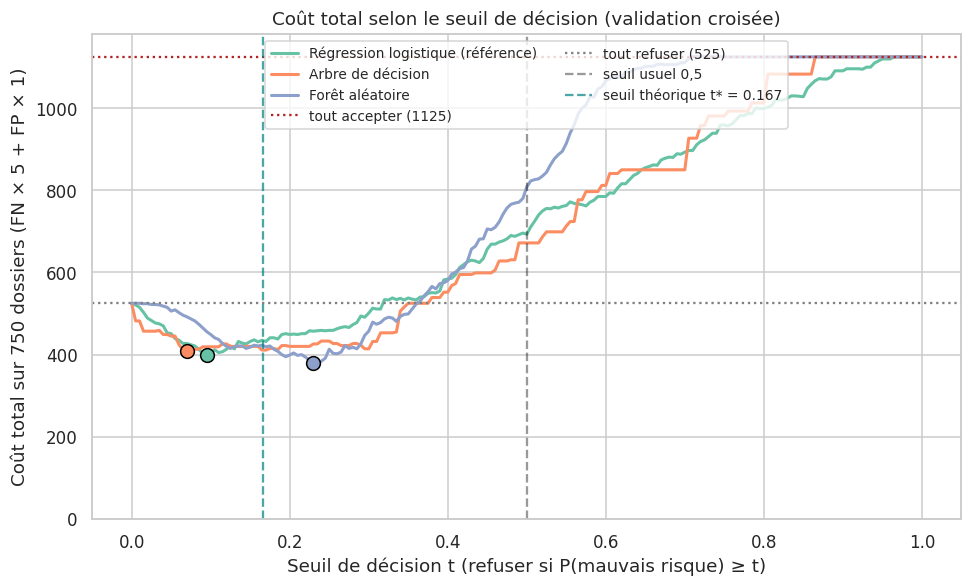

In [17]:
# Courbe de coût selon le seuil, pour les trois modèles (probabilités hors pli, entraînement)
couleurs = dict(zip(pipelines, sns.color_palette("Set2", 3)))

fig, ax = plt.subplots(figsize=(9, 5.5))
for nom, cout in courbes_oof.items():
    ax.plot(seuils, cout, label=nom, color=couleurs[nom], lw=2)
    ax.plot(seuil_optimal(cout), cout.min(), "o", color=couleurs[nom], markersize=9,
            markeredgecolor="k", zorder=5)
ax.axhline(t_acc, color="firebrick", linestyle=":", label=f"tout accepter ({t_acc})")
ax.axhline(t_ref, color="grey", linestyle=":", label=f"tout refuser ({t_ref})")
ax.axvline(0.5, color="k", linestyle="--", alpha=0.4, label="seuil usuel 0,5")
ax.axvline(seuil_theorique, color="teal", linestyle="--", alpha=0.7, label=f"seuil théorique t* = {seuil_theorique:.3f}")
ax.set_xlabel("Seuil de décision t (refuser si P(mauvais risque) ≥ t)")
ax.set_ylabel(f"Coût total sur {len(y_train)} dossiers (FN × {COUT_FN} + FP × {COUT_FP})")
ax.set_title("Coût total selon le seuil de décision (validation croisée)")
ax.set_ylim(0, t_acc * 1.05)
ax.legend(loc="upper center", fontsize=9, ncol=2)
plt.tight_layout()
plt.show()

**Lecture.** Les points marquent le seuil de coût minimal de chaque modèle. Trois constats à vérifier sur la figure :

1. Le minimum se situe **loin de 0,5**, nettement plus à gauche, au voisinage du seuil théorique $t^*$ : à 0,5, le modèle laisse passer trop de mauvais risques, qui coûtent chacun 5.
2. La courbe est **assez plate autour de son minimum** : plusieurs seuils voisins donnent un coût presque identique. Le seuil « optimal » exact est donc peu précis, ce qui annonce l'analyse de sensibilité de la section 9.
3. Aux extrémités, on retrouve les politiques triviales. Le gain du modèle se mesure par la distance entre le minimum de la courbe et la plus basse des deux droites pointillées.

## 8. Évaluation finale sur le jeu de test

Le modèle choisi est entraîné sur tout l'ensemble d'entraînement, puis évalué **une seule fois** sur le jeu de test. Le seuil, lui, est **fixé avant** d'ouvrir le jeu de test, à partir des probabilités hors pli de l'entraînement. Ces scores estiment la performance sur de nouveaux clients.

Nous sélectionnons automatiquement le modèle ayant la meilleure AUC en validation croisée.

In [18]:
# Entraînement de chaque modèle sur tout l'entraînement, puis probabilités sur le test
y_test_np = y_test.to_numpy()
proba_test = {}
for nom, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    proba_test[nom] = pipe.predict_proba(X_test)[:, 1]

# Sélection du meilleur modèle (AUC de validation croisée) et du seuil (probabilités hors pli)
meilleur_nom = tableau.loc[0, "Modèle"]
meilleur_pipe = pipelines[meilleur_nom]
t_retenu = tableau.loc[0, "Seuil optimal"]
p_test = proba_test[meilleur_nom]

print("Meilleur modèle (AUC en validation croisée) :", meilleur_nom)
print(f"Seuil retenu (fixé sur l'entraînement)      : {t_retenu:.3f}")
print()
print("AUC sur le jeu de test :")
for nom, p in proba_test.items():
    print(f"  {nom:36s} {roc_auc_score(y_test_np, p):.3f}")

# Coûts sur le test pour le meilleur modèle
n_acc, n_ref = cout_trivial(y_test_np)
lignes = []
for libelle, s in [("Seuil usuel 0,5", 0.5),
                   (f"Seuil théorique t* = {seuil_theorique:.3f}", seuil_theorique),
                   (f"Seuil retenu = {t_retenu:.3f}", t_retenu)]:
    refuse = p_test >= s
    lignes.append({
        "Règle": libelle,
        "Mauvais risques acceptés (FN)": int(np.sum(~refuse & (y_test_np == 1))),
        "Bons risques refusés (FP)": int(np.sum(refuse & (y_test_np == 0))),
        "Coût total": cout_total(y_test_np, p_test, s),
    })
lignes += [{"Règle": "Tout accepter", "Mauvais risques acceptés (FN)": int(y_test_np.sum()),
            "Bons risques refusés (FP)": 0, "Coût total": n_acc},
           {"Règle": "Tout refuser", "Mauvais risques acceptés (FN)": 0,
            "Bons risques refusés (FP)": int((y_test_np == 0).sum()), "Coût total": n_ref}]
print(f"\nCoûts sur le jeu de test ({len(y_test)} dossiers) :")
pd.DataFrame(lignes)

Meilleur modèle (AUC en validation croisée) : Forêt aléatoire
Seuil retenu (fixé sur l'entraînement)      : 0.230

AUC sur le jeu de test :
  Régression logistique (référence)    0.804
  Arbre de décision                    0.683
  Forêt aléatoire                      0.799

Coûts sur le jeu de test (250 dossiers) :


,Règle,Mauvais risques acceptés (FN),Bons risques refusés (FP),Coût total
0,"Seuil usuel 0,5",47,15,250
1,Seuil théorique t* = 0.167,4,110,130
2,Seuil retenu = 0.230,10,83,133
3,Tout accepter,75,0,375
4,Tout refuser,0,175,175


### 8.1 Courbe ROC et courbe de coût sur le test

La courbe ROC illustre l'AUC. La courbe de coût sur le test est tracée pour le meilleur modèle : le trait vertical montre le seuil retenu **avant** l'examen du test. Le minimum de cette courbe est un point de comparaison, mais il ne faut pas le prendre comme seuil : choisir le seuil sur le test reviendrait à l'ajuster sur les données censées l'évaluer.

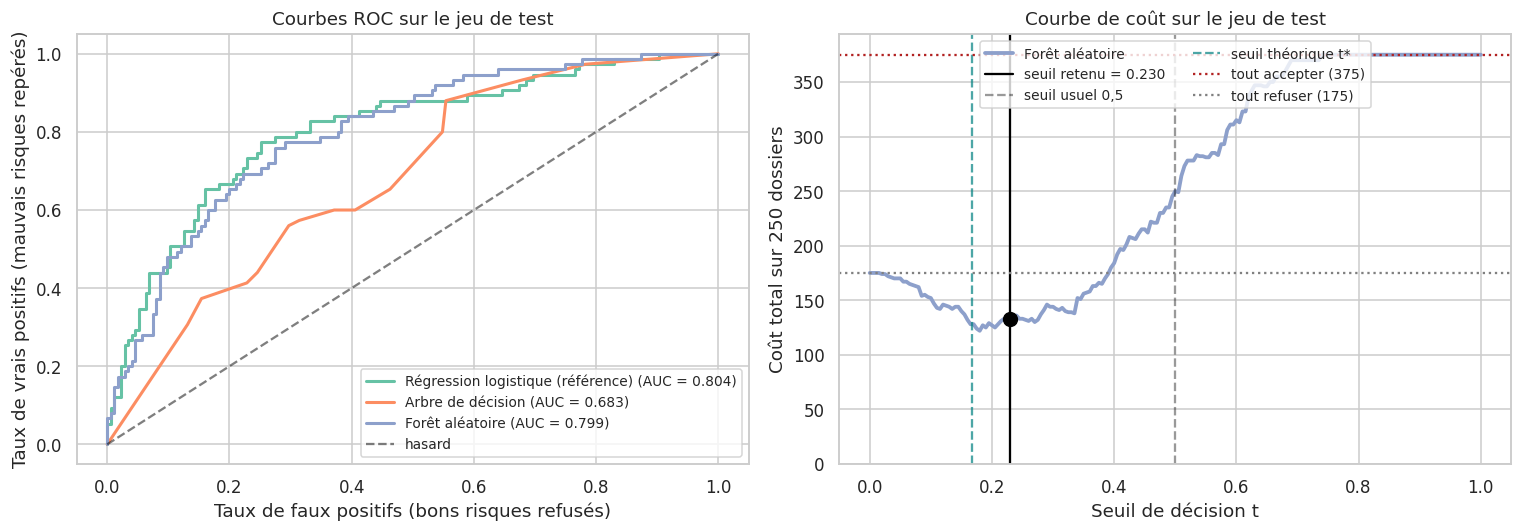

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Courbes ROC des trois modèles sur le test
for nom, p in proba_test.items():
    fpr, tpr, _ = roc_curve(y_test_np, p)
    axes[0].plot(fpr, tpr, lw=2, color=couleurs[nom], label=f"{nom} (AUC = {roc_auc_score(y_test_np, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="hasard")
axes[0].set_xlabel("Taux de faux positifs (bons risques refusés)")
axes[0].set_ylabel("Taux de vrais positifs (mauvais risques repérés)")
axes[0].set_title("Courbes ROC sur le jeu de test")
axes[0].legend(loc="lower right", fontsize=9)

# Courbe de coût du meilleur modèle sur le test
cout_test = courbe_cout(y_test_np, p_test)
axes[1].plot(seuils, cout_test, color=couleurs[meilleur_nom], lw=2.5, label=meilleur_nom)
axes[1].axvline(t_retenu, color="k", linestyle="-", label=f"seuil retenu = {t_retenu:.3f}")
axes[1].plot(t_retenu, cout_total(y_test_np, p_test, t_retenu), "o", color="k", markersize=9, zorder=5)
axes[1].axvline(0.5, color="k", linestyle="--", alpha=0.4, label="seuil usuel 0,5")
axes[1].axvline(seuil_theorique, color="teal", linestyle="--", alpha=0.7, label="seuil théorique t*")
axes[1].axhline(n_acc, color="firebrick", linestyle=":", label=f"tout accepter ({n_acc})")
axes[1].axhline(n_ref, color="grey", linestyle=":", label=f"tout refuser ({n_ref})")
axes[1].set_xlabel("Seuil de décision t")
axes[1].set_ylabel(f"Coût total sur {len(y_test)} dossiers")
axes[1].set_title("Courbe de coût sur le jeu de test")
axes[1].set_ylim(0, n_acc * 1.05)
axes[1].legend(loc="upper center", fontsize=9, ncol=2)
plt.tight_layout()
plt.show()

**Lecture.** Le jeu de test ne comporte que 250 dossiers dont environ 75 mauvais risques : la courbe de coût est **plus irrégulière** que celle de la validation croisée, et son minimum bouge facilement d'un échantillon à l'autre. C'est une raison de plus pour ne pas choisir le seuil sur le test. Vérifiez que le coût au seuil retenu est bien inférieur à celui du seuil 0,5 et à la meilleure politique triviale.

### 8.2 Matrice de confusion

La matrice de confusion croise la classe réelle et la décision. Avec des coûts asymétriques, la case la plus importante est celle des **mauvais risques acceptés** (faux négatifs), pondérée par 5.

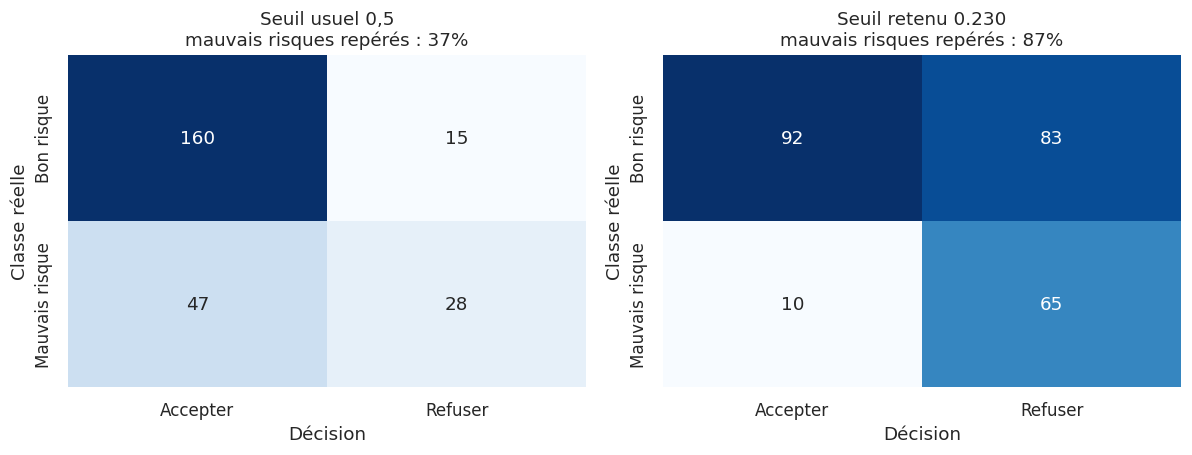

In [20]:
# Matrices de confusion au seuil 0,5 et au seuil retenu
decisions = ["Accepter", "Refuser"]
reels = ["Bon risque", "Mauvais risque"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, (titre, s) in zip(axes, [("Seuil usuel 0,5", 0.5), (f"Seuil retenu {t_retenu:.3f}", t_retenu)]):
    cm = confusion_matrix(y_test_np, (p_test >= s).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=decisions,
                yticklabels=reels, cbar=False, ax=ax)
    rappel = cm[1, 1] / cm[1].sum()
    ax.set_title(f"{titre}\nmauvais risques repérés : {rappel:.0%}")
    ax.set_xlabel("Décision")
    ax.set_ylabel("Classe réelle")
plt.tight_layout()
plt.show()

**Lecture.** Abaisser le seuil augmente le nombre de **bons clients refusés** (case en haut à droite), ce qui est le prix à payer pour repérer davantage de **mauvais risques** (case en bas à droite). C'est un échange voulu : chaque mauvais risque évité rapporte 5, chaque bon client perdu coûte 1. Une banque qui refuserait 40 à 50 % de ses bons clients pour repérer la plupart des défauts doit toutefois se demander si cet arbitrage est acceptable commercialement : le coût de 1 pour un client perdu est une hypothèse, ce qui nous amène à la section 9.

### 8.3 Courbe d'apprentissage

La courbe d'apprentissage répond à une question pratique : **le modèle manque-t-il de données, ou de flexibilité ?** On utilise ici l'AUC comme mesure.

- Si les courbes d'entraînement et de validation convergent vers un score faible : **sous-apprentissage** (biais élevé).
- Si l'écart reste grand : **surapprentissage** (variance élevée) ; plus de données ou une régularisation aideraient.

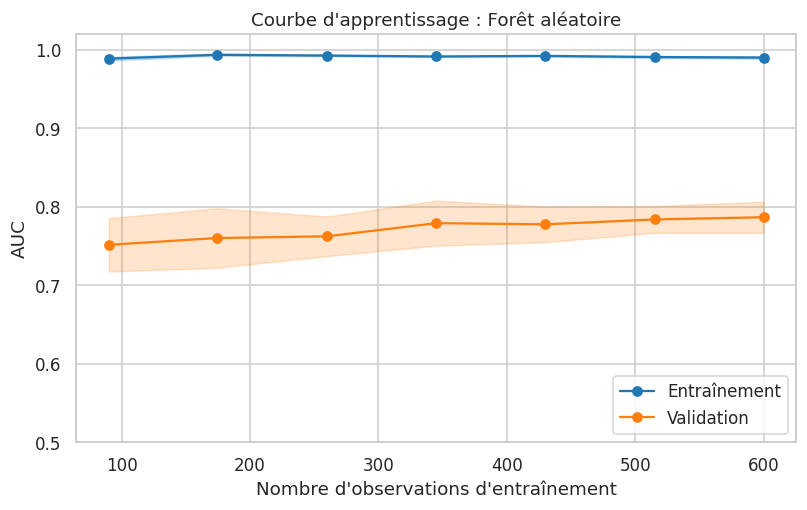

In [21]:
# Courbe d'apprentissage du meilleur modèle (AUC)
tailles, scores_train, scores_val = learning_curve(
    meilleur_pipe, X_train, y_train,
    train_sizes=np.linspace(0.15, 1.0, 7), cv=validation, scoring="roc_auc", n_jobs=-1
)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
for scores, label, couleur in [(scores_train, "Entraînement", "tab:blue"),
                               (scores_val, "Validation", "tab:orange")]:
    moyenne, ecart = scores.mean(axis=1), scores.std(axis=1)
    ax.plot(tailles, moyenne, "o-", color=couleur, label=label)
    ax.fill_between(tailles, moyenne - ecart, moyenne + ecart, alpha=0.2, color=couleur)
ax.set_xlabel("Nombre d'observations d'entraînement")
ax.set_ylabel("AUC")
ax.set_title(f"Courbe d'apprentissage : {meilleur_nom}")
ax.set_ylim(0.5, 1.02)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Lecture.** Observez l'écart entre la courbe d'entraînement et celle de validation. Pour une forêt aléatoire, l'AUC en entraînement est très proche de 1 (les arbres mémorisent les données), alors que l'AUC de validation plafonne beaucoup plus bas : c'est du surapprentissage, qui ne rend pas le modèle mauvais pour autant, car c'est la courbe de **validation** qui compte. Si cette dernière monte encore à droite, davantage de dossiers amélioreraient le modèle ; si elle est déjà à plat, le facteur limitant est l'information contenue dans les variables, pas la quantité de données.

## 9. Analyse de sensibilité aux hypothèses de coût

**Le risque principal de ce TP :** le seuil optimal dépend entièrement du rapport de coûts $r = c_{FN}/c_{FP}$, que nous avons posé à 5 sans pouvoir le mesurer précisément. Une banque réelle aurait des coûts qui varient selon le montant, le type de crédit et la conjoncture. Il faut donc montrer **dans quelle mesure les conclusions changent** si ce rapport varie.

On fait varier $r$ de 1 (erreurs symétriques) à 20 (mauvais risque très coûteux), en gardant $c_{FP}=1$. Pour chaque valeur :

- le **seuil optimal** est recalculé sur les probabilités hors pli ;
- le coût est exprimé **par dossier** (pour comparer des valeurs de $r$ différentes) ;
- on mesure le **regret** si l'on garde le seuil calculé pour $r=5$ alors que le vrai rapport est différent.

In [22]:
# Analyse de sensibilité pour le meilleur modèle
ratios = [1, 2, 3, 5, 10, 20]
p_oof = proba_oof[meilleur_nom]
n_tr, n_te = len(y_train_np), len(y_test_np)

# Seuil retenu pour le rapport de référence r = 5
t_ref5 = seuil_optimal(courbe_cout(y_train_np, p_oof, c_fn=5, c_fp=1))

lignes, courbes_r = [], {}
for r in ratios:
    cout = courbe_cout(y_train_np, p_oof, c_fn=r, c_fp=1)
    courbes_r[r] = cout
    t_opt = seuil_optimal(cout)
    tolerance = seuils[cout <= 1.05 * cout.min()]           # seuils à moins de 5 % du minimum
    cout_adapte = cout_total(y_test_np, p_test, t_opt, r, 1) / n_te
    cout_fige = cout_total(y_test_np, p_test, t_ref5, r, 1) / n_te
    triv = min(cout_trivial(y_test_np, r, 1)) / n_te
    lignes.append({
        "Rapport r": r,
        "Seuil théorique 1/(1+r)": 1 / (1 + r),
        "Seuil optimal (CV)": t_opt,
        "Plage à ±5 % du coût min": f"[{tolerance.min():.2f} ; {tolerance.max():.2f}]",
        "Coût/dossier test (seuil adapté)": cout_adapte,
        "Coût/dossier test (seuil fixé à r=5)": cout_fige,
        "Regret": cout_fige - cout_adapte,
        "Meilleure politique triviale": triv,
    })

sensibilite = pd.DataFrame(lignes)
print(f"Meilleur modèle : {meilleur_nom} | seuil retenu pour r = 5 : {t_ref5:.3f}")
sensibilite.round(3)

Meilleur modèle : Forêt aléatoire | seuil retenu pour r = 5 : 0.230


,Rapport r,Seuil théorique 1/(1+r),Seuil optimal (CV),Plage à ±5 % du coût min,Coût/dossier test (seuil adapté),Coût/dossier test (seuil fixé à r=5),Regret,Meilleure politique triviale
0,1,0.500,0.425,[0.42 ; 0.49],0.240,0.372,0.132,0.3
1,2,0.333,0.350,[0.28 ; 0.42],0.360,0.412,0.052,0.6
2,3,0.250,0.285,[0.23 ; 0.29],0.444,0.452,0.008,0.7
3,5,0.167,0.230,[0.20 ; 0.24],0.532,0.532,0.000,0.7
4,10,0.091,0.125,[0.12 ; 0.14],0.620,0.732,0.112,0.7
5,20,0.048,0.125,[0.11 ; 0.13],0.700,1.132,0.432,0.7


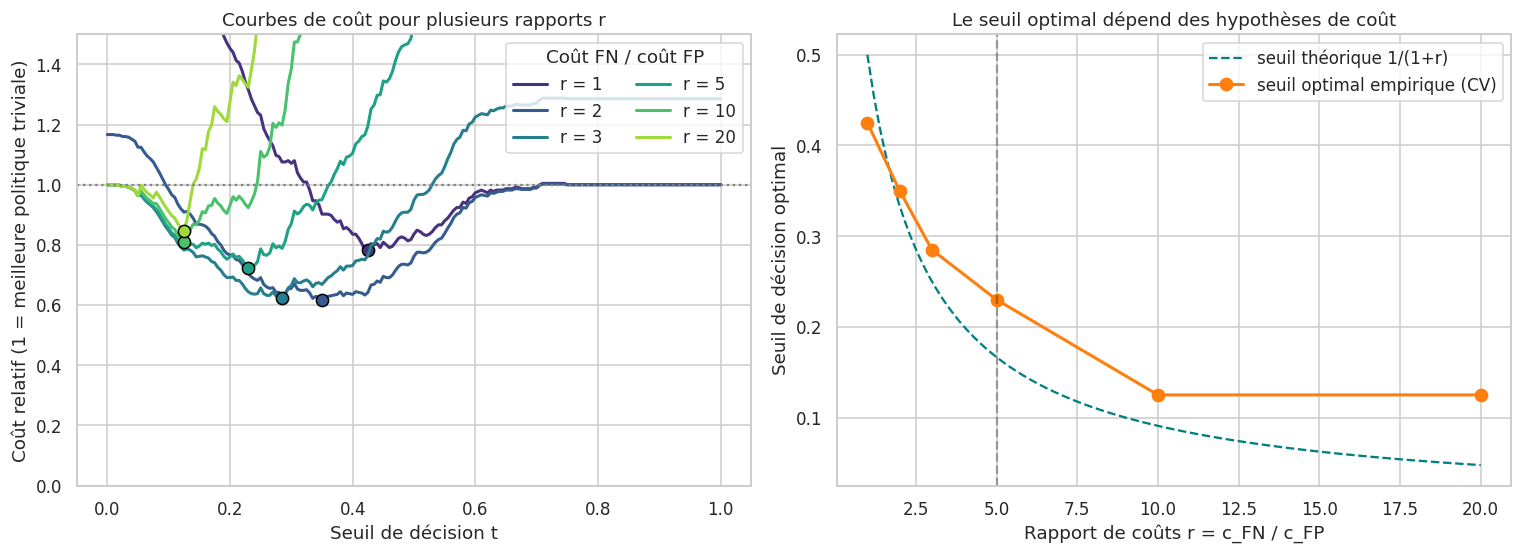

In [23]:
# Graphiques de sensibilité
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
palette = sns.color_palette("viridis", len(ratios))

# Gauche : courbes de coût relatives (1 = meilleure politique triviale)
for couleur, r in zip(palette, ratios):
    cout = courbes_r[r]
    triv = min(cout_trivial(y_train_np, r, 1))
    axes[0].plot(seuils, cout / triv, color=couleur, lw=2, label=f"r = {r}")
    axes[0].plot(seuil_optimal(cout), cout.min() / triv, "o", color=couleur, markeredgecolor="k", markersize=8)
axes[0].axhline(1, color="grey", linestyle=":")
axes[0].set_ylim(0, 1.5)
axes[0].set_xlabel("Seuil de décision t")
axes[0].set_ylabel("Coût relatif (1 = meilleure politique triviale)")
axes[0].set_title("Courbes de coût pour plusieurs rapports r")
axes[0].legend(title="Coût FN / coût FP", loc="upper right", ncol=2)

# Droite : seuil optimal en fonction de r
r_fin = np.linspace(1, 20, 100)
axes[1].plot(r_fin, 1 / (1 + r_fin), "--", color="teal", label="seuil théorique 1/(1+r)")
axes[1].plot(ratios, sensibilite["Seuil optimal (CV)"], "o-", color="tab:orange", lw=2, markersize=8,
             label="seuil optimal empirique (CV)")
axes[1].axvline(5, color="k", alpha=0.3, linestyle="--")
axes[1].set_xlabel("Rapport de coûts r = c_FN / c_FP")
axes[1].set_ylabel("Seuil de décision optimal")
axes[1].set_title("Le seuil optimal dépend des hypothèses de coût")
axes[1].legend()
plt.tight_layout()
plt.show()

**Lecture.** Trois enseignements attendus :

1. **Le seuil optimal diminue quand $r$ augmente** : plus un mauvais risque coûte cher, plus la banque doit être exigeante, au prix de refuser davantage de bons clients. Pour $r=1$ le seuil est proche de 0,5 ; pour $r=20$ il est très bas.
2. **Le seuil empirique suit le seuil théorique $1/(1+r)$ mais s'en écarte**, surtout aux valeurs extrêmes de $r$. Les probabilités d'un modèle ne sont pas parfaitement calibrées (c'est particulièrement vrai pour un arbre ou une forêt), et le minimum est estimé sur un échantillon limité.
3. **Lorsque $r$ est grand, le gain sur la politique triviale s'amenuise** : si un mauvais risque coûte 20 fois plus cher, le plus sûr devient de refuser presque tout le monde, et le modèle apporte peu. À l'inverse, la colonne « Regret » indique ce que l'on perd à garder un seuil calculé pour $r=5$ quand le vrai rapport est différent : un regret faible signifie que la décision est robuste.

Retenez la conclusion pratique : **on ne communique pas « le » seuil optimal, mais un seuil accompagné de la plage de rapports de coûts pour laquelle il reste raisonnable.**

### 9.1 Le meilleur modèle change-t-il avec les coûts ?

Le classement des modèles selon l'AUC ne dépend pas des coûts, mais le classement selon le **coût minimal** peut en dépendre. Vérifions-le.

In [24]:
# Coût minimal par dossier (probabilités hors pli) pour chaque modèle et chaque rapport r
tab_modeles = {}
for nom, p in proba_oof.items():
    tab_modeles[nom] = [courbe_cout(y_train_np, p, c_fn=r, c_fp=1).min() / n_tr for r in ratios]
comparaison = pd.DataFrame(tab_modeles, index=[f"r = {r}" for r in ratios]).T
meilleurs = comparaison.idxmin(axis=0)
print("Modèle de coût minimal pour chaque rapport :")
print(meilleurs.to_string())
print("\nCoût minimal par dossier (validation croisée) :")
comparaison.round(3)

Modèle de coût minimal pour chaque rapport :
r = 1       Forêt aléatoire
r = 2     Arbre de décision
r = 3     Arbre de décision
r = 5       Forêt aléatoire
r = 10      Forêt aléatoire
r = 20      Forêt aléatoire

Coût minimal par dossier (validation croisée) :


,r = 1,r = 2,r = 3,r = 5,r = 10,r = 20
Régression logistique (référence),0.248,0.381,0.468,0.531,0.611,0.671
Arbre de décision,0.263,0.360,0.424,0.544,0.649,0.700
Forêt aléatoire,0.235,0.369,0.437,0.507,0.567,0.593


**Lecture.** Si le même modèle arrive en tête pour tous les rapports, le choix du modèle est robuste aux hypothèses de coût ; sinon, la recommandation doit être conditionnelle (« pour $r \le 3$, le modèle A ; au-delà, le modèle B »). Gardez en tête que les écarts de coût entre modèles sont souvent petits devant l'incertitude d'estimation : une différence de quelques millièmes par dossier n'est pas significative.

## 10. Interpréter les modèles : quels attributs signalent un mauvais risque ?

C'est la question posée au départ. Deux outils complémentaires :

- les **coefficients de la régression logistique**, qui indiquent le sens de l'effet de chaque modalité (un coefficient positif augmente la probabilité de mauvais risque, « toutes choses égales par ailleurs ») ;
- l'**importance par permutation** : on mélange au hasard les valeurs d'une variable du jeu de test et on mesure la baisse d'AUC. Plus la baisse est forte, plus le modèle s'appuie sur cette variable. Cet outil s'applique à n'importe quel modèle et regroupe automatiquement les colonnes issues du même attribut.

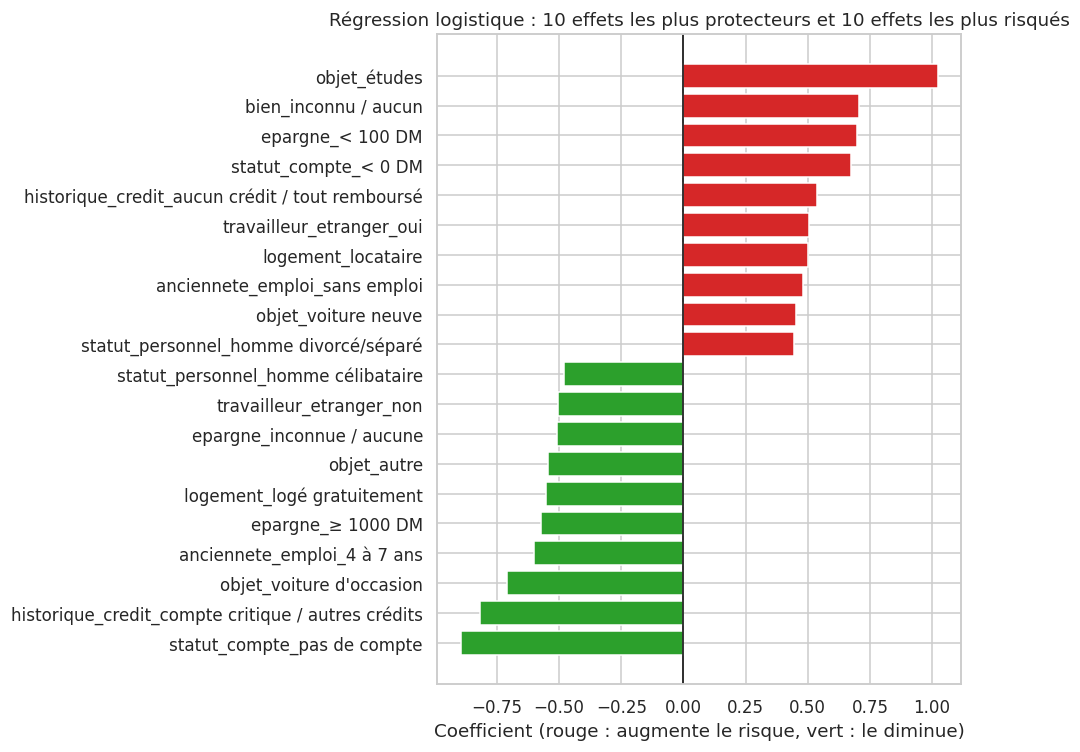

Les 5 modalités ou variables associées au risque le plus élevé :
objet_études                                       1.02
bien_inconnu / aucun                               0.71
epargne_< 100 DM                                   0.70
statut_compte_< 0 DM                               0.67
historique_credit_aucun crédit / tout remboursé    0.54


In [25]:
# 10.1 Coefficients de la régression logistique (variables numériques standardisées)
nom_lr = "Régression logistique (référence)"
lr = pipelines[nom_lr]                      # déjà entraînée sur tout l'entraînement
noms_col = lr.named_steps["prep"].get_feature_names_out()
noms_col = [n.replace("num__", "").replace("cat__", "") for n in noms_col]
coefs = pd.Series(lr.named_steps["modele"].coef_[0], index=noms_col).sort_values()

extremes = pd.concat([coefs.head(10), coefs.tail(10)])
fig, ax = plt.subplots(figsize=(9, 7))
couleurs_bar = ["tab:green" if v < 0 else "tab:red" for v in extremes]
ax.barh(extremes.index, extremes.values, color=couleurs_bar)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("Coefficient (rouge : augmente le risque, vert : le diminue)")
ax.set_title("Régression logistique : 10 effets les plus protecteurs et 10 effets les plus risqués")
plt.tight_layout()
plt.show()

print("Les 5 modalités ou variables associées au risque le plus élevé :")
print(coefs.tail(5).iloc[::-1].round(2).to_string())

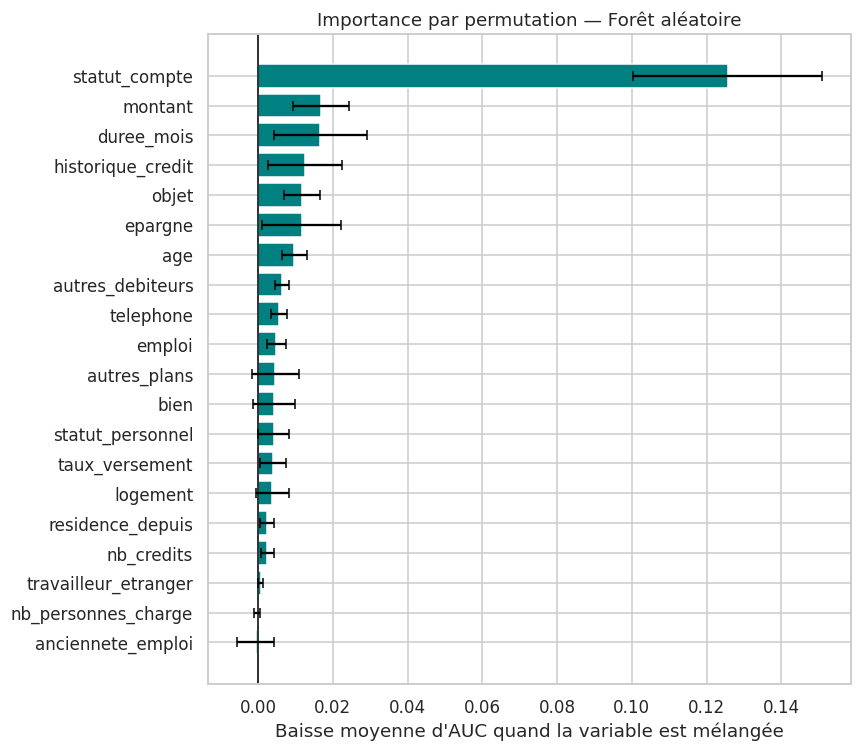

Les 5 attributs les plus importants :
statut_compte        0.1257
montant              0.0168
duree_mois           0.0166
historique_credit    0.0126
objet                0.0117


In [26]:
# 10.2 Importance par permutation (sur le jeu de test) du meilleur modèle
perm = permutation_importance(meilleur_pipe, X_test, y_test, scoring="roc_auc",
                              n_repeats=30, random_state=42, n_jobs=-1)
importance = pd.DataFrame({"moyenne": perm.importances_mean, "ecart": perm.importances_std},
                          index=X_test.columns).sort_values("moyenne")

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(importance.index, importance["moyenne"], xerr=importance["ecart"], color="teal", capsize=3)
ax.axvline(0, color="k", lw=1)
ax.set_xlabel("Baisse moyenne d'AUC quand la variable est mélangée")
ax.set_title(f"Importance par permutation — {meilleur_nom}")
plt.tight_layout()
plt.show()

print("Les 5 attributs les plus importants :")
print(importance["moyenne"].tail(5).iloc[::-1].round(4).to_string())

**Lecture.** Les deux méthodes convergent en général sur les attributs qui comptent :

- le **statut du compte courant** (découvert ou absence de compte), la **durée** et le **montant** du crédit, l'**historique de crédit**, l'**épargne** et l'**objet** du prêt figurent parmi les attributs les plus informatifs ;
- l'âge, le logement ou la profession ont un effet plus modeste ;
- certaines variables ont une importance nulle, voire légèrement négative : mélanger leurs valeurs n'abîme pas, ou améliore à peine, la prédiction. Ce sont des variables que le modèle n'utilise pas à bon escient.

**Précautions.** Ce sont des **associations**, pas des causes : on ne peut pas affirmer qu'un changement de statut de compte ferait varier le risque. Les importances sont instables quand les variables sont corrélées (durée et montant). Enfin, ce jeu de données contient des variables sensibles (sexe et situation personnelle, âge, statut d'étranger) : un modèle utilisé réellement pour décider d'un crédit devrait être examiné du point de vue de l'équité et du droit applicable, ce qui dépasse le cadre de ce TP.

## 11. Décider pour un nouveau dossier

Une fois le modèle et le seuil validés, on peut décider du sort d'un nouveau dossier. Le pipeline applique automatiquement la même standardisation et le même encodage qu'à l'entraînement. L'espérance de coût de chaque décision se calcule directement avec les probabilités.

In [27]:
# Nouveau dossier fictif, construit à partir d'un client du jeu de test dont on modifie quelques attributs
nouveau = X_test.iloc[[0]].copy()
nouveau["duree_mois"] = 36
nouveau["montant"] = 6500
nouveau["statut_compte"] = "< 0 DM"
nouveau["epargne"] = "< 100 DM"
print(nouveau.T.to_string())

p_nouveau = meilleur_pipe.predict_proba(nouveau)[0, 1]
cout_accepter = p_nouveau * COUT_FN            # on perd 5 si c'est un mauvais risque
cout_refuser = (1 - p_nouveau) * COUT_FP       # on perd 1 si c'est un bon risque

print(f"\nProbabilité estimée de mauvais risque : {p_nouveau:.3f}")
print(f"Coût espéré si on accepte : {cout_accepter:.2f} | si on refuse : {cout_refuser:.2f}")
print(f"Seuil retenu : {t_retenu:.3f} -> décision :", "REFUSER" if p_nouveau >= t_retenu else "ACCEPTER")

                                                522
statut_compte                                < 0 DM
duree_mois                                       36
historique_credit     aucun crédit / tout remboursé
objet                                       meubles
montant                                        6500
epargne                                    < 100 DM
anciennete_emploi                         1 à 4 ans
taux_versement                                    3
statut_personnel                  homme célibataire
autres_debiteurs                              aucun
residence_depuis                                  4
bien                                inconnu / aucun
age                                              53
autres_plans                                  aucun
logement                          logé gratuitement
nb_credits                                        2
emploi                                     qualifié
nb_personnes_charge                               2
telephone   

## 12. Synthèse

### Ce qu'il faut retenir

1. **Type d'apprentissage** : supervisé, classification binaire, avec des coûts d'erreur asymétriques. La classe positive est le mauvais risque.
2. **Deux étapes distinctes** : le modèle estime une *probabilité* de mauvais risque (qualité mesurée par l'AUC) ; le *seuil* transforme cette probabilité en décision (qualité mesurée par le coût).
3. **Le seuil usuel 0,5 est inadapté** quand les erreurs n'ont pas le même coût : le seuil théorique est $c_{FP}/(c_{FP}+c_{FN})$, ici environ 0,17.
4. **Le seuil se fixe sans regarder le test** : on le choisit sur des probabilités hors pli, et on n'utilise le test qu'une fois pour vérifier.
5. **Le seuil optimal dépend des hypothèses de coût** : il faut accompagner toute recommandation d'une analyse de sensibilité, et idéalement donner une plage de seuils robustes plutôt qu'une valeur unique.
6. **Interprétation** : les attributs qui signalent un mauvais risque sont surtout le statut du compte, la durée, le montant, l'historique de crédit et l'épargne ; ce sont des associations, pas des causes.

